In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

# OVReader figures

Reproduces the OVReader data charts (paper `fig:ovreader` main figure `ov_reader_combined` + the
appendix per-pivot figure `ov_by_pivot_combined`) and saves PDFs (+PNG) to `notebooks/Figures/ovreader/`.

Data is read straight from `results/evaluation/ov-reader/<model>/<layer>/<mode>/<leaf>/summary.json`
via the shared IO helper `scripts/evaluation/ov_reader_io.py` (`grid_df` -> per-(layer, pivot, datatype)
`hard_yes`). The `goalscope` layer dir is the head-output reference (dashed line), **not** a probe layer.
Main pivot position is `eq` (the assignment pivot); the `first_impl` pivot is excluded throughout.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import figstyle
from scripts.evaluation import ov_reader_io as ovio

figstyle.set_style()

MODEL   = "Qwen/Qwen2.5-Coder-32B-Instruct"
MSLUG   = MODEL.split("/")[-1]
PIVOT   = "eq"                      # assignment pivot = main OVReader position
RR      = env_utils.determine_results_dir()
SKY     = ovio.SKYLINE_IDX          # "goalscope"

def load_metric(mode, pivot=PIVOT):
    """Return (layers, dtypes, {dt: hard_yes-over-layers}, {dt: goalscope-ref}) at `pivot`."""
    df = ovio.grid_df(RR, mode=mode, model=MODEL)
    df = df[df["pivot"] == pivot]
    piv = df.pivot_table(index="layer_idx", columns="datatype", values="hard_yes")
    dtypes = sorted(piv.columns.tolist())
    ref = {dt: (piv.loc[SKY, dt] if SKY in piv.index else np.nan) for dt in dtypes}
    piv = piv.drop(index=SKY, errors="ignore")
    layers = sorted(int(x) for x in piv.index)
    curves = {dt: piv.loc[layers, dt].to_numpy(dtype=float) for dt in dtypes}
    return layers, dtypes, curves, ref

FAI = load_metric("faithfulness")
CAU = load_metric("causality")
DTYPES = FAI[1]
DT_COLOR = {dt: figstyle.OKABE_ITO[i] for i, dt in enumerate(DTYPES)}
print("layers:", FAI[0])
print("datatypes:", DTYPES)
print("pre-impl pivots available in figstyle:", figstyle.PIVOTS)

layers: [0, 6, 12, 18, 24, 30, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 60, 63]
datatypes: ['int', 'list[int]', 'list[str]', 'str']
pre-impl pivots available in figstyle: ['prev_end', 'indent', 'var', 'eq']


## Fig 3 - `ov_reader_combined` (main-body `fig:ovreader`)

Main-body figure showing the overlap between OVReader read-out success and goal-head density across
layers. Curves (both **black**): faithfulness (**solid**) and causality (**tight dash** `(0,(5,1.2))`)
`hard_yes` vs. source layer, averaged over the 4 pre-implementation pivots (prev_end, indent, var, eq;
`first_impl` excluded) *and* the 4 datatypes. Overlay: the 122-head goal set's per-layer head count
(loaded from `head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json`) as a faint gold
background histogram on a secondary right axis ("goal heads per layer", capped at 20) — the read-out
peaks where the goal heads concentrate (~L45-52). Single-row legend on top.

122-head set across layers 28-55; peak 12 heads @ L49


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ovreader/ov_reader_combined.pdf
faithfulness peak (4-pivot mean) = 0.771 @ layer 50 | goalscope ref = 0.853
causality    peak (4-pivot mean) = 0.723 @ layer 50 | goalscope ref = 0.749
goal-head density peak @ L49 (mass in L45-52: 68/122)


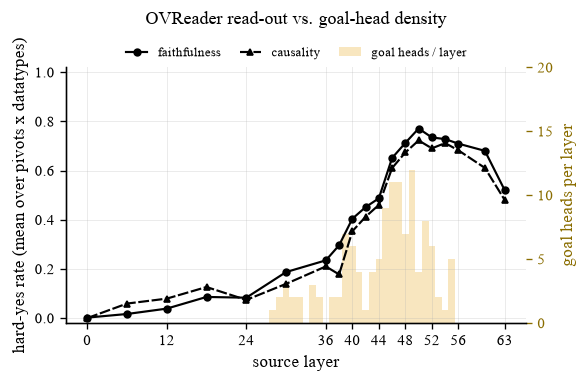

In [6]:
import json, collections
CAUS_DASH = (0, (5, 1.2))          # tight dashes = causality style (shared)

# ── readout: mean over the 4 pre-impl pivots AND the 4 datatypes ──
def metric_over_pivots(mode):
    """(layers, mean-hard_yes over 4 pivots x 4 datatypes, goalscope-ref mean)."""
    per_pivot_means, refs = [], []
    x = None
    for piv in figstyle.PIVOTS:                      # prev_end, indent, var, eq (no first_impl)
        layers, _, curves, ref = load_metric(mode, piv)
        x = np.array(layers)
        per_pivot_means.append(np.nanmean(np.stack([curves[dt] for dt in DTYPES]), axis=0))
        refs.append(np.nanmean([ref[dt] for dt in DTYPES]))
    return x, np.nanmean(np.stack(per_pivot_means), axis=0), float(np.nanmean(refs))

xf, mf, rf = metric_over_pivots("faithfulness")
xc, mc, rc = metric_over_pivots("causality")

# ── goal-head density per layer (122-head set), loaded from the head_set file ──
HEAD_SET = "head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json"
_pairs = json.load(open(HEAD_SET))
_counts = collections.Counter(l for l, h in _pairs)
dens_layers = np.array(sorted(_counts))
dens_counts = np.array([_counts[l] for l in dens_layers])
print(f"{len(_pairs)}-head set across layers {dens_layers.min()}-{dens_layers.max()};"
      f" peak {dens_counts.max()} heads @ L{int(dens_layers[dens_counts.argmax()])}")

GOLD = "#E69F00"
LW, MS = 1.3, 4                    # thinner curves, slightly smaller markers

fig, ax = plt.subplots(figsize=(5.0, 3.3))

# density overlay on a faint secondary right axis, drawn BEHIND the curves
ax2 = ax.twinx()
ax2.bar(dens_layers, dens_counts, width=1.0, color=GOLD, alpha=0.25, zorder=0, linewidth=0)
ax2.set_ylabel("goal heads per layer", color="#8a6d00")
ax2.tick_params(axis="y", colors="#8a6d00")
ax2.set_ylim(0, 20)
ax2.set_yticks([0, 5, 10, 15, 20])
ax2.grid(False)
# put the curve axis on top of the density bars
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

# readout curves: both BLACK, faithfulness solid, causality tight-dash
ax.plot(xf, mf, marker="o", ms=MS, lw=LW, color="black", ls="-", label="faithfulness", zorder=5)
ax.plot(xc, mc, marker="^", ms=MS, lw=LW, color="black", ls=CAUS_DASH, label="causality", zorder=5)

ax.set_xlabel("source layer")
ax.set_ylabel("hard-yes rate (mean over pivots x datatypes)")
ax.set_title(r"OVReader read-out vs. goal-head density")
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(xf[::2])

# legend: single row on top, just below the title
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
handles = [
    Line2D([], [], color="black", ls="-", marker="o", ms=MS, lw=LW, label="faithfulness"),
    Line2D([], [], color="black", ls=CAUS_DASH, marker="^", ms=MS, lw=LW, label="causality"),
    Patch(facecolor=GOLD, alpha=0.25, label="goal heads / layer"),
]
figstyle.legend_top(ax, handles=handles, labels=[h.get_label() for h in handles], fontsize=8)
fig.tight_layout()
p = figstyle.save_fig(fig, "ovreader", "ov_reader_combined")
print("saved", p)
print(f"faithfulness peak (4-pivot mean) = {np.nanmax(mf):.3f} @ layer {int(xf[np.nanargmax(mf)])} "
      f"| goalscope ref = {rf:.3f}")
print(f"causality    peak (4-pivot mean) = {np.nanmax(mc):.3f} @ layer {int(xc[np.nanargmax(mc)])} "
      f"| goalscope ref = {rc:.3f}")
print(f"goal-head density peak @ L{int(dens_layers[dens_counts.argmax()])} "
      f"(mass in L45-52: {dens_counts[(dens_layers>=45)&(dens_layers<=52)].sum()}/{dens_counts.sum()})")

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ovreader/ov_by_pivot_combined.pdf


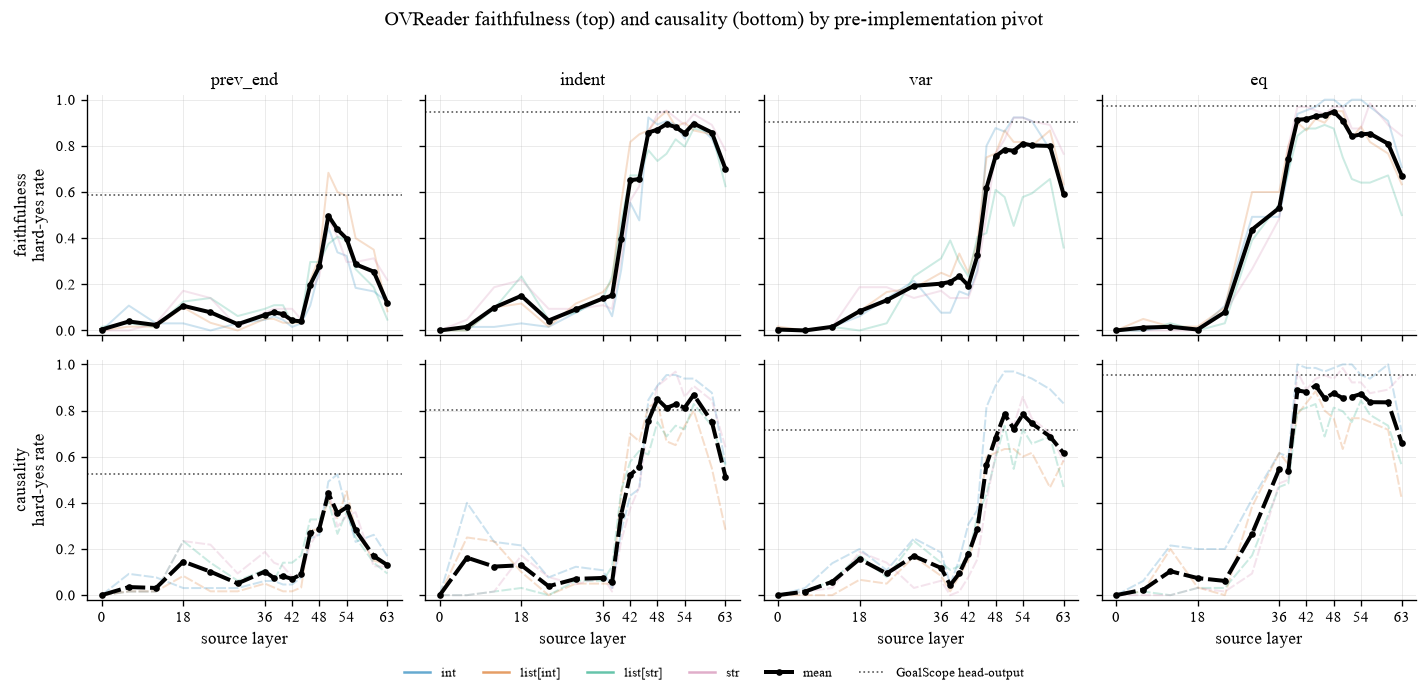

In [9]:
# 2-ROW combined per-pivot figure: row 0 = faithfulness, row 1 = causality (4 pre-impl pivots).
# Merges fig:ov-faithfulness + fig:ov-causality into one appendix figure (ov_by_pivot_combined).
from matplotlib.lines import Line2D
PANEL_PIVOTS = list(figstyle.PIVOTS)
CAUS_DASH = (0, (5, 1.2))

def plot_by_pivot_combined(save_name="ov_by_pivot_combined"):
    modes = [("faithfulness", "-"), ("causality", CAUS_DASH)]
    fig, axes = plt.subplots(len(modes), len(PANEL_PIVOTS),
                             figsize=(3.0 * len(PANEL_PIVOTS), 2.7 * len(modes)),
                             sharex=True, sharey=True)
    for row, (mode, ls) in enumerate(modes):
        for col, piv in enumerate(PANEL_PIVOTS):
            ax = axes[row, col]
            layers, _, curves, ref = load_metric(mode, piv)
            x = np.array(layers)
            mean = np.nanmean(np.stack([curves[dt] for dt in DTYPES]), axis=0)
            refm = float(np.nanmean([ref[dt] for dt in DTYPES]))
            for dt in DTYPES:
                ax.plot(x, curves[dt], lw=1.2, ls=ls, color=DT_COLOR[dt], alpha=0.2)
            ax.plot(x, mean, marker="o", ms=3, lw=2.4, ls=ls, color="black", zorder=5)
            ax.axhline(refm, ls=":", lw=1.0, color="0.35")
            ax.set_ylim(-0.02, 1.02)
            ax.set_xticks(x[::3])
            if row == 0:
                ax.set_title(piv)
            if row == len(modes) - 1:
                ax.set_xlabel("source layer")
        axes[row, 0].set_ylabel(f"{mode}\nhard-yes rate")
    handles = ([Line2D([], [], color=DT_COLOR[dt], lw=1.5, alpha=0.6, label=dt) for dt in DTYPES]
               + [Line2D([], [], color="black", marker="o", ms=3, lw=2.4, label="mean"),
                  Line2D([], [], color="0.35", ls=":", lw=1.0, label="GoalScope head-output")])
    fig.legend(handles=handles, frameon=False, fontsize=8, ncol=len(handles),
               loc="lower center", bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("OVReader faithfulness (top) and causality (bottom) by pre-implementation pivot", y=1.01)
    fig.tight_layout()
    p = figstyle.save_fig(fig, "ovreader", save_name)
    print("saved", p)
    return fig

_ = plot_by_pivot_combined()